### Task 1: Simple Linear Regression

This section demonstrates how to implement simple linear regression using a sample dataset and print its coefficients.

In [1]:
import numpy as np
from sklearn.linear_model import LinearRegression

# Sample dataset
X = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10]).reshape(-1, 1) # Features
y = np.array([2, 4, 5, 4, 5, 7, 8, 9, 10, 12]) # Target

# Create and train the model
model = LinearRegression()
model.fit(X, y)

# Print the coefficients
print(f"Intercept: {model.intercept_}")
print(f"Coefficient: {model.coef_[0]}")

Intercept: 1.0666666666666673
Coefficient: 1.0060606060606059


### Task 2: Load a Regression Dataset

Here, we load the Diabetes dataset from scikit-learn, display its feature names, and the target variable name.

In [2]:
from sklearn.datasets import load_diabetes

# Load the Diabetes dataset
diabetes = load_diabetes()

# Display feature names
print("Feature Names:")
for feature in diabetes.feature_names:
    print(f"- {feature}")

# Display target variable name (Diabetes dataset doesn't have a specific target name string, it's implied)
print("\nTarget Variable: Diabetes Progression (quantitative measure of disease progression one year after baseline)")

Feature Names:
- age
- sex
- bmi
- bp
- s1
- s2
- s3
- s4
- s5
- s6

Target Variable: Diabetes Progression (quantitative measure of disease progression one year after baseline)


### Task 3: Split Dataset and Apply Linear Regression

This section demonstrates splitting the Diabetes dataset into training and testing sets and applying a Linear Regression model.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Use the Diabetes dataset loaded in Task 2
X_diabetes = diabetes.data
y_diabetes = diabetes.target

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_diabetes, y_diabetes, test_size=0.2, random_state=42)

# Create and train the Linear Regression model
lin_reg_model = LinearRegression()
lin_reg_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = lin_reg_model.predict(X_test)

# Evaluate the model
print(f"Linear Regression Coefficients: {lin_reg_model.coef_}")
print(f"Linear Regression Intercept: {lin_reg_model.intercept_}")
print(f"Mean Squared Error: {mean_squared_error(y_test, y_pred):.2f}")
print(f"R-squared: {r2_score(y_test, y_pred):.2f}")

Linear Regression Coefficients: [  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]
Linear Regression Intercept: 151.34560453985995
Mean Squared Error: 2900.19
R-squared: 0.45


### Task 4: Plot the Regression Line

This code plots the regression line for the simple linear regression model created in Task 1.

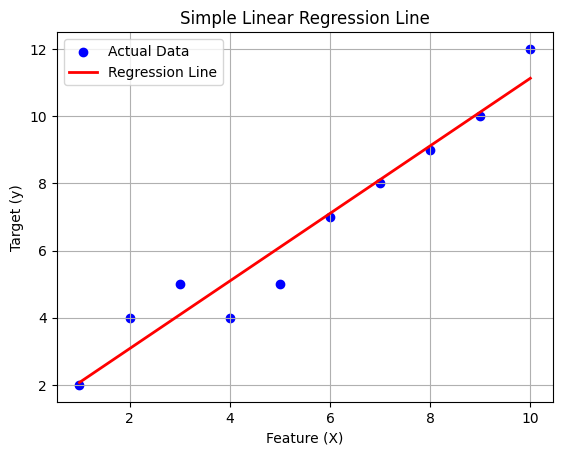

In [4]:
import matplotlib.pyplot as plt

# Use the model and data from Task 1
# X = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10]).reshape(-1, 1)
# y = np.array([2, 4, 5, 4, 5, 7, 8, 9, 10, 12])
# model = LinearRegression()
# model.fit(X, y)

# Generate predictions for the regression line
y_pred_line = model.predict(X)

# Plot the actual data points
plt.scatter(X, y, color='blue', label='Actual Data')

# Plot the regression line
plt.plot(X, y_pred_line, color='red', linewidth=2, label='Regression Line')

plt.title('Simple Linear Regression Line')
plt.xlabel('Feature (X)')
plt.ylabel('Target (y)')
plt.legend()
plt.grid(True)
plt.show()

### Task 5: K-Means Clustering on Iris Dataset

This section applies K-Means clustering to the classic Iris dataset.

In [5]:
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
import pandas as pd

# Load the Iris dataset
iris = load_iris()
X_iris = iris.data

# Choose the number of clusters (Iris has 3 species)
k = 3

# Apply K-Means clustering
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10) # n_init explicitly set for newer sklearn versions
kmeans.fit(X_iris)

# Get cluster labels
cluster_labels = kmeans.labels_

print(f"K-Means Cluster Labels (first 10): {cluster_labels[:10]}")
print(f"\nCluster Centers:\n{kmeans.cluster_centers_}")

# Optionally, add cluster labels to a DataFrame for easier viewing
iris_df = pd.DataFrame(X_iris, columns=iris.feature_names)
iris_df['cluster'] = cluster_labels
print("\nIris DataFrame with Cluster Labels (first 5 rows):\n", iris_df.head())

K-Means Cluster Labels (first 10): [1 1 1 1 1 1 1 1 1 1]

Cluster Centers:
[[5.9016129  2.7483871  4.39354839 1.43387097]
 [5.006      3.428      1.462      0.246     ]
 [6.85       3.07368421 5.74210526 2.07105263]]

Iris DataFrame with Cluster Labels (first 5 rows):
    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   cluster  
0        1  
1        1  
2        1  
3        1  
4        1  


### Task 6: Cross-Validation for Linear Regression

We'll use cross-validation to evaluate the performance of a Linear Regression model on the Diabetes dataset.

In [6]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

# Use the Diabetes dataset loaded in Task 2
# X_diabetes = diabetes.data
# y_diabetes = diabetes.target

# Create a Linear Regression model
lin_reg_cv_model = LinearRegression()

# Perform 5-fold cross-validation using negative mean squared error
# (sklearn's cross_val_score returns negative values for error metrics, so we negate them)
rmse_scores = np.sqrt(-cross_val_score(lin_reg_cv_model, X_diabetes, y_diabetes, cv=5, scoring='neg_mean_squared_error'))

print(f"Cross-validated RMSE scores: {rmse_scores}")
print(f"Average RMSE: {np.mean(rmse_scores):.2f}")
print(f"Standard deviation of RMSE: {np.std(rmse_scores):.2f}")

Cross-validated RMSE scores: [52.72497937 55.03486476 56.90068179 54.85204179 53.94638716]
Average RMSE: 54.69
Standard deviation of RMSE: 1.37


### Task 7: Standardize Dataset Before K-Means Clustering

This section demonstrates standardizing the Iris dataset using `StandardScaler` and then applying K-Means clustering to the scaled data.

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import pandas as pd

# Use the Iris dataset loaded in Task 5
# X_iris = iris.data

# Initialize StandardScaler
scaler = StandardScaler()

# Standardize the data
X_iris_scaled = scaler.fit_transform(X_iris)

# Apply K-Means clustering to the scaled data
k = 3
kmeans_scaled = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans_scaled.fit(X_iris_scaled)

cluster_labels_scaled = kmeans_scaled.labels_

print(f"K-Means Cluster Labels on Scaled Data (first 10): {cluster_labels_scaled[:10]}")
print(f"\nCluster Centers (Scaled):\n{kmeans_scaled.cluster_centers_}")

# Create a DataFrame for scaled data with cluster labels
iris_scaled_df = pd.DataFrame(X_iris_scaled, columns=iris.feature_names)
iris_scaled_df['cluster'] = cluster_labels_scaled
print("\nScaled Iris DataFrame with Cluster Labels (first 5 rows):\n", iris_scaled_df.head())

K-Means Cluster Labels on Scaled Data (first 10): [1 1 1 1 1 1 1 1 1 1]

Cluster Centers (Scaled):
[[-0.05021989 -0.88337647  0.34773781  0.2815273 ]
 [-1.01457897  0.85326268 -1.30498732 -1.25489349]
 [ 1.13597027  0.08842168  0.99615451  1.01752612]]

Scaled Iris DataFrame with Cluster Labels (first 5 rows):
    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0          -0.900681          1.019004          -1.340227         -1.315444   
1          -1.143017         -0.131979          -1.340227         -1.315444   
2          -1.385353          0.328414          -1.397064         -1.315444   
3          -1.506521          0.098217          -1.283389         -1.315444   
4          -1.021849          1.249201          -1.340227         -1.315444   

   cluster  
0        1  
1        1  
2        1  
3        1  
4        1  


### Task 8: Check Multicollinearity using Correlation Matrix

We will check for multicollinearity in the Diabetes dataset by computing and visualizing its correlation matrix.

Correlation Matrix:
           age       sex       bmi        bp        s1        s2        s3  \
age  1.000000  0.173737  0.185085  0.335428  0.260061  0.219243 -0.075181   
sex  0.173737  1.000000  0.088161  0.241010  0.035277  0.142637 -0.379090   
bmi  0.185085  0.088161  1.000000  0.395411  0.249777  0.261170 -0.366811   
bp   0.335428  0.241010  0.395411  1.000000  0.242464  0.185548 -0.178762   
s1   0.260061  0.035277  0.249777  0.242464  1.000000  0.896663  0.051519   
s2   0.219243  0.142637  0.261170  0.185548  0.896663  1.000000 -0.196455   
s3  -0.075181 -0.379090 -0.366811 -0.178762  0.051519 -0.196455  1.000000   
s4   0.203841  0.332115  0.413807  0.257650  0.542207  0.659817 -0.738493   
s5   0.270774  0.149916  0.446157  0.393480  0.515503  0.318357 -0.398577   
s6   0.301731  0.208133  0.388680  0.390430  0.325717  0.290600 -0.273697   

           s4        s5        s6  
age  0.203841  0.270774  0.301731  
sex  0.332115  0.149916  0.208133  
bmi  0.413807  0.446157

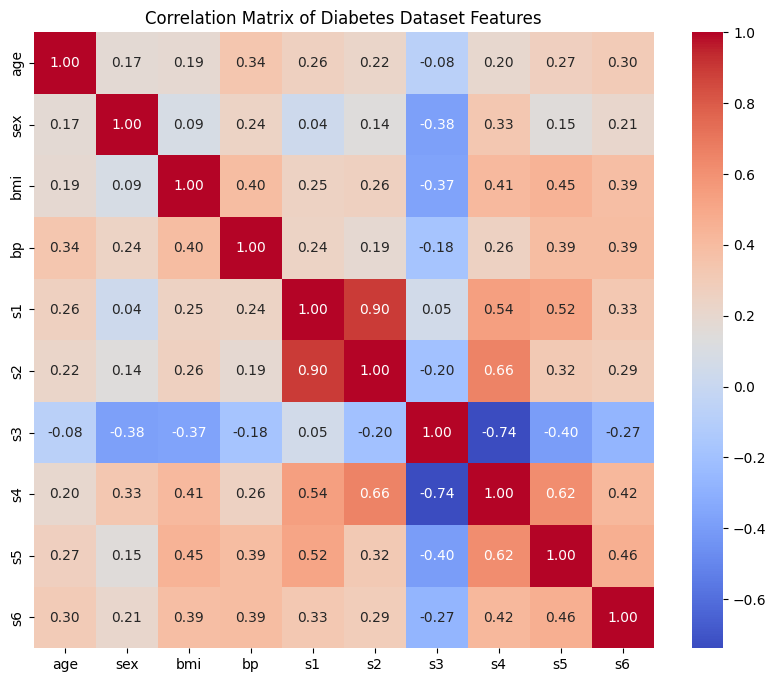

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Use the Diabetes dataset loaded in Task 2
# X_diabetes = diabetes.data
# diabetes.feature_names

# Create a DataFrame from the features
diabetes_df_features = pd.DataFrame(X_diabetes, columns=diabetes.feature_names)

# Calculate the correlation matrix
correlation_matrix = diabetes_df_features.corr()

print("Correlation Matrix:\n", correlation_matrix)

# Visualize the correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Diabetes Dataset Features')
plt.show()

### Task 9: Visualize K-Means Clusters using Pair Plots

This section visualizes the K-Means clusters (from Task 5) on the Iris dataset using Seaborn's pair plots.

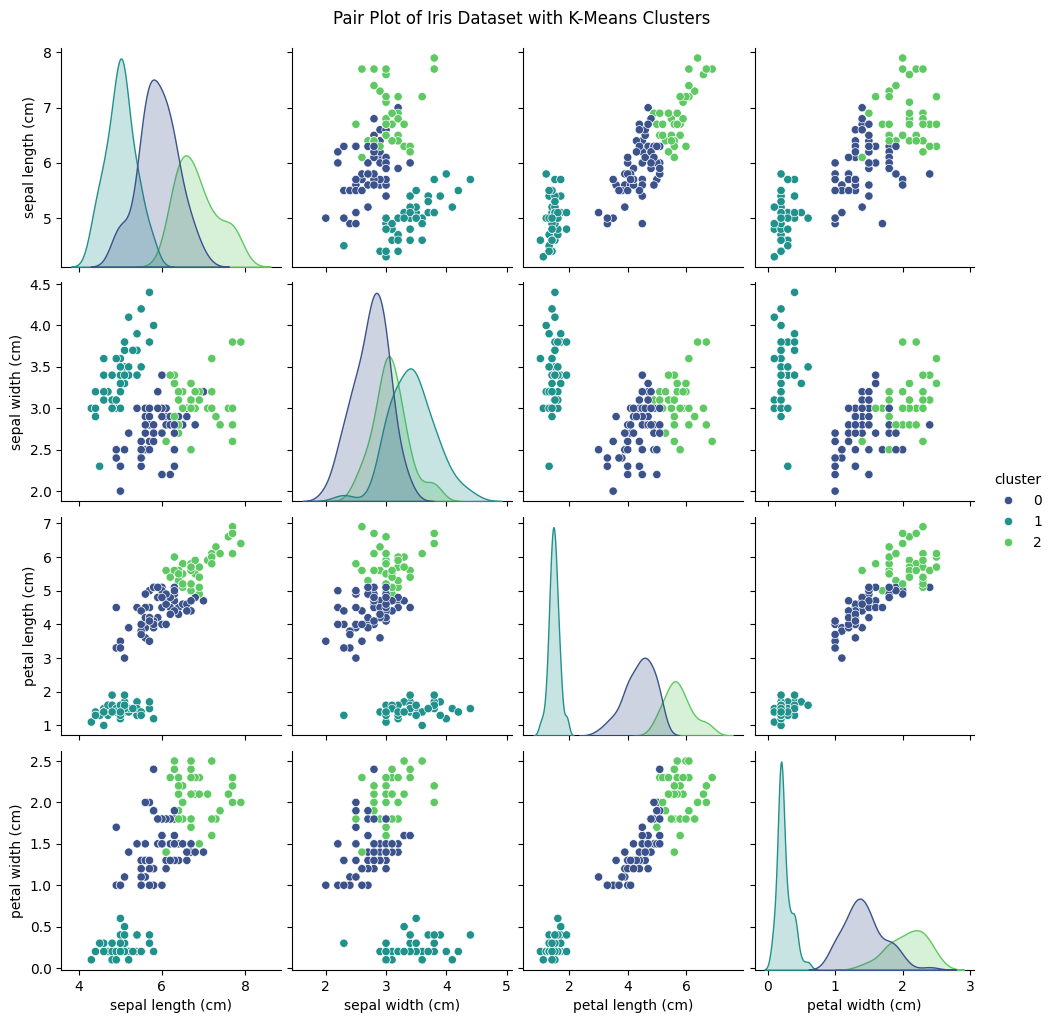

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Use the Iris data and cluster labels from Task 5
# X_iris = iris.data
# iris.feature_names
# cluster_labels = kmeans.labels_

# Create a DataFrame with features and cluster labels
iris_df_clustered = pd.DataFrame(X_iris, columns=iris.feature_names)
iris_df_clustered['cluster'] = cluster_labels

# Convert cluster column to categorical for better plotting
iris_df_clustered['cluster'] = iris_df_clustered['cluster'].astype('category')

# Create a pair plot
sns.pairplot(iris_df_clustered, hue='cluster', palette='viridis', diag_kind='kde')
plt.suptitle('Pair Plot of Iris Dataset with K-Means Clusters', y=1.02) # Adjust title position
plt.show()

### Task 10: K-Means Clustering on a Real-World CSV Dataset and Display Cluster Counts

This example simulates loading a CSV, applying K-Means, and displaying the counts of data points in each cluster.

In [10]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import io

# Simulate a real-world CSV dataset
csv_data = """feature_a,feature_b,feature_c
1.0,2.1,0.5
1.2,2.0,0.4
1.1,2.2,0.6
5.0,8.0,7.1
5.2,7.9,7.0
5.1,8.1,7.2
9.0,1.0,2.0
9.1,1.2,2.1
9.2,1.1,2.2
"""
df_csv = pd.read_csv(io.StringIO(csv_data))

print("Original DataFrame from CSV:\n", df_csv)

# Select features for clustering
X_csv = df_csv[['feature_a', 'feature_b', 'feature_c']]

# It's good practice to scale data before K-Means
scaler_csv = StandardScaler()
X_csv_scaled = scaler_csv.fit_transform(X_csv)

# Apply K-Means clustering
k_csv = 3 # Assuming 3 clusters for this sample data
kmeans_csv = KMeans(n_clusters=k_csv, random_state=42, n_init=10)
kmeans_csv.fit(X_csv_scaled)

# Get cluster labels
cluster_labels_csv = kmeans_csv.labels_

# Add cluster labels to the DataFrame
df_csv['cluster'] = cluster_labels_csv

print("\nDataFrame with Cluster Labels:\n", df_csv)

# Display cluster counts
cluster_counts = df_csv['cluster'].value_counts().sort_index()
print("\nCluster Counts:\n", cluster_counts)

Original DataFrame from CSV:
    feature_a  feature_b  feature_c
0        1.0        2.1        0.5
1        1.2        2.0        0.4
2        1.1        2.2        0.6
3        5.0        8.0        7.1
4        5.2        7.9        7.0
5        5.1        8.1        7.2
6        9.0        1.0        2.0
7        9.1        1.2        2.1
8        9.2        1.1        2.2

DataFrame with Cluster Labels:
    feature_a  feature_b  feature_c  cluster
0        1.0        2.1        0.5        2
1        1.2        2.0        0.4        2
2        1.1        2.2        0.6        2
3        5.0        8.0        7.1        0
4        5.2        7.9        7.0        0
5        5.1        8.1        7.2        0
6        9.0        1.0        2.0        1
7        9.1        1.2        2.1        1
8        9.2        1.1        2.2        1

Cluster Counts:
 cluster
0    3
1    3
2    3
Name: count, dtype: int64
